Updated for Great Plains SOC from `Data/00_shared/data_geostatistics/Data_GP/gp_data_5000.csv`. The sections below are the sample map, variograms, held-out predictions, and the core versus JAX comparison.

![Banner](../images/02_kriging.png)

# Simple, ordinary, universal, and cokriging on Great Plains SOC

**Library:** `geolattice.geostatistics` and `geolattice.geostatistics.jax_variogram_kriging`

**Data:** `Data/00_shared/data_geostatistics/Data_GP/gp_data_5000.csv` (5,000 samples). Target is SOC. Cokriging uses NDVI as the secondary variable (correlation with SOC about 0.77).

***


## Contents

1. [What is compared](#what-is-compared)
2. [Great Plains sample](#great-plains-sample)
3. [Variograms](#variograms)
4. [Predictions](#predictions)
5. [Predicted maps](#predicted-maps)
6. [Comparison](#comparison)
7. [Timing](#timing)
8. [Getting good performance from JAX kriging](#getting-good-performance-from-jax-kriging)
9. [Reading the figures](#reading-the-figures)

## What is compared

| Estimator | Core class | JAX class | Data |
|-----------|------------|-----------|------|
| Simple kriging | `SimpleKriging` | `jax_variogram_kriging.SimpleKriging` | SOC, training mean |
| Ordinary kriging | `OrdinaryKriging` | `jax_variogram_kriging.OrdinaryKriging` | SOC |
| Universal kriging | `UniversalKriging` | `jax_variogram_kriging.UniversalKriging` | SOC, linear drift in x and y |
| Ordinary cokriging | `Cokriging` | `jax_variogram_kriging.Cokriging` | SOC with NDVI |

Coordinates are stored in metres. The notebook shifts them to the sample mean and divides by 1,000, so lags and the universal-kriging drift are in kilometres. A full 5,000 by 5,000 kriging system is too large to solve four ways on three backends, so the variograms use 2,000 samples and the kriging systems use 600 training locations and 250 held-out locations, all drawn from this file.


**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
import os
import time

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from geolattice.geostatistics.core.variogram import Variogram as CoreVariogram
from geolattice.geostatistics.core.kriging import OrdinaryKriging as CoreOK
from geolattice.geostatistics.core.kriging import SimpleKriging as CoreSK
from geolattice.geostatistics.kriging.universal_kriging import UniversalKriging as CoreUK
from geolattice.geostatistics.kriging.cokriging import Cokriging as CoreCK
from geolattice.geostatistics.kriging.cokriging import CrossVariogram as CoreCross
from geolattice.geostatistics import jax_variogram_kriging as jx

DATA_PATH = "../../../../Data/00_shared/data_geostatistics/Data_GP/gp_data_5000.csv"
MODEL = "spherical"
N_LAGS = 12
N_VARIO = 2000
N_TRAIN = 600
N_TEST = 250
rng = np.random.default_rng(7)

gpu_devices = [d for d in jx.jax.devices() if d.platform in ("gpu", "cuda", "rocm")]
JAX_MAP = "JAX GPU" if gpu_devices else "JAX CPU"
print("JAX devices:", jx.jax.devices())
print("Map backend:", JAX_MAP)


JAX devices: [CudaDevice(id=0)]
Map backend: JAX GPU


## Great Plains sample

SOC is the primary variable. NDVI is the secondary used by cokriging. The map shows every sample in the file. The orange points are the 250 locations held out of the kriging fit.


5000 rows, columns: x, y, Aspect, ELEV, FRG, K_Factor, MAP, MAT ...
SOC  min 0.03  mean 6.03  max 23.75
NDVI min 0.05  mean 0.41  max 0.82
correlation SOC, NDVI = 0.771
coordinates in km relative to (-754423 m, 1765231 m)
variogram maxlag 716 km on 2000 samples
kriging train 600, test 250


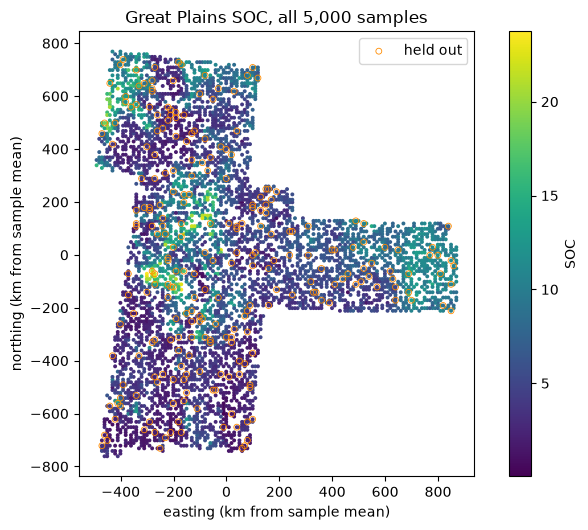

In [2]:
gp = pd.read_csv(DATA_PATH)
print(f"{len(gp)} rows, columns: {', '.join(gp.columns[:8])} ...")
xy_m = gp[["x", "y"]].to_numpy(dtype=float)
origin = xy_m.mean(axis=0)
xy = (xy_m - origin) / 1000.0
soc = gp["SOC"].to_numpy(dtype=float)
ndvi = gp["NDVI"].to_numpy(dtype=float)
print(f"SOC  min {soc.min():.2f}  mean {soc.mean():.2f}  max {soc.max():.2f}")
print(f"NDVI min {ndvi.min():.2f}  mean {ndvi.mean():.2f}  max {ndvi.max():.2f}")
print(f"correlation SOC, NDVI = {np.corrcoef(soc, ndvi)[0, 1]:.3f}")
print(f"coordinates in km relative to ({origin[0]:.0f} m, {origin[1]:.0f} m)")

order = rng.permutation(len(gp))
vario_idx = order[:N_VARIO]
train_idx = order[:N_TRAIN]
test_idx = order[N_TRAIN:N_TRAIN + N_TEST]
train_xy, test_xy = xy[train_idx], xy[test_idx]
train_z, test_z = soc[train_idx], soc[test_idx]
train_s, test_s = ndvi[train_idx], ndvi[test_idx]

span = np.ptp(xy, axis=0)
MAXLAG = float(min(800.0, 0.35 * np.hypot(*span)))
print(f"variogram maxlag {MAXLAG:.0f} km on {N_VARIO} samples")
print(f"kriging train {N_TRAIN}, test {N_TEST}")

fig, ax = plt.subplots(figsize=(7.2, 5.4))
sc = ax.scatter(xy[:, 0], xy[:, 1], c=soc, s=8, cmap="viridis", linewidths=0)
ax.scatter(test_xy[:, 0], test_xy[:, 1], facecolors="none", edgecolors="darkorange", s=18, linewidths=0.6, label="held out")
ax.set_aspect("equal")
ax.set_xlabel("easting (km from sample mean)")
ax.set_ylabel("northing (km from sample mean)")
ax.set_title("Great Plains SOC, all 5,000 samples")
ax.legend(loc="upper right")
fig.colorbar(sc, ax=ax, label="SOC")
fig.tight_layout()
plt.show()


## Variograms

The spherical model is fit on the same 2,000 samples by the core and by JAX. The plots show the empirical bins and the fitted curve for SOC, for NDVI, and for the SOC-NDVI cross-variogram. JAX curves use the parameters fitted on that backend, so a small shift between the two lines is a difference in the fit, not in the plot.


,nugget,partial sill,range (km)
variogram,,,
SOC core,4.2448,9.4747,295.4575
SOC JAX,4.2448,9.4747,295.4580
NDVI core,0.0055,0.0176,358.2374
NDVI JAX,0.0055,0.0176,358.2374
cross core,0.0816,0.3485,334.5346
cross JAX,0.0816,0.3485,334.5245


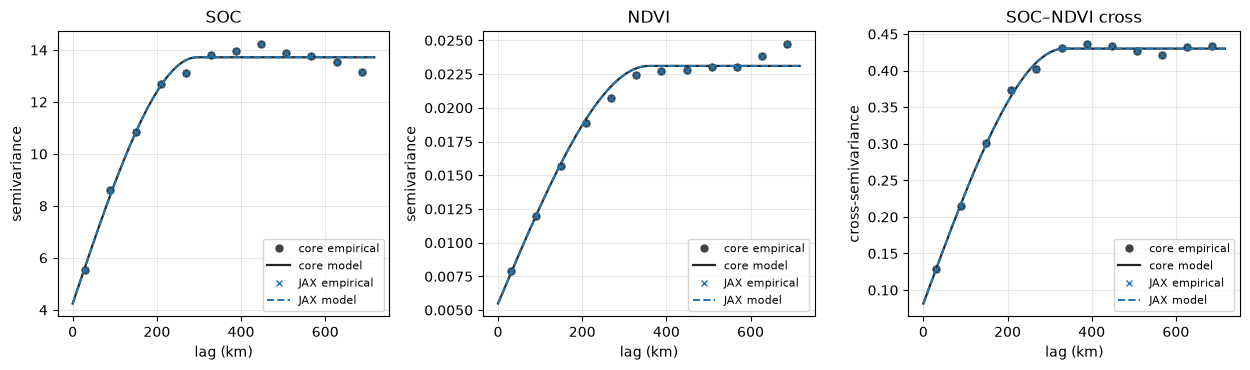

In [3]:
def fit_pair(coords, values, use_gpu, jax_backend):
    cls = jx.Variogram if jax_backend else CoreVariogram
    return cls(coords, values, model=MODEL, maxlag=MAXLAG, n_lags=N_LAGS, use_gpu=use_gpu).fit()


vario_xy, vario_z, vario_s = xy[vario_idx], soc[vario_idx], ndvi[vario_idx]
# Variograms stay on CPU. A 2,000-point pairwise matrix is small there,
# and the GPU comparison is the kriging solve below.
core_soc = fit_pair(vario_xy, vario_z, False, False)
jax_soc = fit_pair(vario_xy, vario_z, False, True)
core_ndvi = fit_pair(vario_xy, vario_s, False, False)
jax_ndvi = fit_pair(vario_xy, vario_s, False, True)
core_cross = CoreCross(
    vario_xy, vario_z, vario_s, maxlag=MAXLAG, n_lags=N_LAGS, model=MODEL, use_gpu=False
).fit(method="auto")
jax_cross = jx.CrossVariogram(
    vario_xy, vario_z, vario_s, maxlag=MAXLAG, n_lags=N_LAGS, model=MODEL, use_gpu=False
).fit(method="auto")

def param_row(name, variogram):
    nugget, sill, range_ = [float(v) for v in variogram.fitted_params[:3]]
    return {"variogram": name, "nugget": nugget, "partial sill": sill, "range (km)": range_}

param_table = pd.DataFrame([
    param_row("SOC core", core_soc),
    param_row("SOC JAX", jax_soc),
    param_row("NDVI core", core_ndvi),
    param_row("NDVI JAX", jax_ndvi),
    param_row("cross core", core_cross),
    param_row("cross JAX", jax_cross),
]).set_index("variogram")
display(param_table.round(4))

def draw_variogram(ax, core_v, jax_v, title, ylab):
    h = np.linspace(0, MAXLAG, 200)
    ax.plot(core_v.lags, core_v.experimental, "o", color="0.25", ms=5, label="core empirical")
    ax.plot(h, np.asarray(core_v(h)), color="0.15", lw=1.6, label="core model")
    ax.plot(jax_v.lags, jax_v.experimental, "x", color="C0", ms=5, label="JAX empirical")
    ax.plot(h, np.asarray(jax_v(h)), color="C0", lw=1.4, ls="--", label="JAX model")
    ax.set_xlabel("lag (km)")
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.8))
draw_variogram(axes[0], core_soc, jax_soc, "SOC", "semivariance")
draw_variogram(axes[1], core_ndvi, jax_ndvi, "NDVI", "semivariance")
draw_variogram(axes[2], core_cross, jax_cross, "SOC–NDVI cross", "cross-semivariance")
fig.tight_layout()
plt.show()


## Predictions

Kriging uses the first 600 of the same random draw, and scores the next 250. JAX models are given the core parameters, so the maps compare the solvers. Simple kriging uses the training mean of SOC. Universal kriging uses a degree-1 drift in the kilometre coordinates. Cokriging borrows NDVI at the same training sites.


In [4]:
def with_core_params(cls, coords, values, source, use_gpu):
    model = cls(coords, values, model=MODEL, maxlag=MAXLAG, n_lags=N_LAGS, use_gpu=use_gpu)
    model.set_params(*[float(v) for v in source.fitted_params])
    return model


def jax_cross_from_core(use_gpu):
    cross = jx.CrossVariogram(
        train_xy, train_z, train_s, maxlag=MAXLAG, n_lags=N_LAGS, model=MODEL, use_gpu=use_gpu
    )
    cross.set_params(*[float(v) for v in core_cross.fitted_params])
    return cross


# Variograms above were fit on 2,000 samples. Kriging uses those parameters
# on the 600 training locations.
known_mean = float(train_z.mean())
backends = {"core CPU": dict(use_gpu=False, jax=False), "JAX CPU": dict(use_gpu=False, jax=True)}
if gpu_devices:
    backends["JAX GPU"] = dict(use_gpu=True, jax=True)


def predict_method(method, backend):
    use_gpu = backend["use_gpu"]
    if backend["jax"]:
        primary = with_core_params(jx.Variogram, train_xy, train_z, core_soc, use_gpu)
        if method == "SK":
            model = jx.SimpleKriging(primary, mean=known_mean, use_gpu=use_gpu).fit(train_xy, train_z)
        elif method == "OK":
            model = jx.OrdinaryKriging(primary, use_gpu=use_gpu).fit(train_xy, train_z)
        elif method == "UK":
            model = jx.UniversalKriging(primary, degree=1, use_gpu=use_gpu).fit(train_xy, train_z)
        else:
            secondary = with_core_params(jx.Variogram, train_xy, train_s, core_ndvi, use_gpu)
            model = jx.Cokriging(primary, secondary, jax_cross_from_core(use_gpu), use_gpu=use_gpu).fit(
                train_xy, train_z, train_xy, train_s
            )
        return model.predict(test_xy, return_variance=True)
    if method == "SK":
        model = CoreSK(core_soc, mean=known_mean, use_gpu=False).fit(train_xy, train_z)
    elif method == "OK":
        model = CoreOK(core_soc, use_gpu=False).fit(train_xy, train_z)
    elif method == "UK":
        model = CoreUK(core_soc, degree=1, use_gpu=False).fit(train_xy, train_z)
    else:
        model = CoreCK(core_soc, core_ndvi, core_cross, use_gpu=False).fit(
            train_xy, train_z, train_xy, train_s
        )
    return model.predict(test_xy, return_variance=True)


methods = ["SK", "OK", "UK", "CK"]
predictions = {}
rows = []
for method in methods:
    for label, backend in backends.items():
        pred, se = predict_method(method, backend)
        pred = np.asarray(pred, dtype=float)
        predictions[(method, label)] = pred
        gap = 0.0 if label == "core CPU" else float(np.max(np.abs(pred - predictions[(method, "core CPU")])))
        rows.append({
            "method": method,
            "backend": label,
            "RMSE": float(np.sqrt(np.mean((pred - test_z) ** 2))),
            "MAE": float(np.mean(np.abs(pred - test_z))),
            "mean SE": float(np.mean(se)),
            "max |JAX − core|": gap,
        })

scores = pd.DataFrame(rows)
display(scores.round(4))


,method,backend,RMSE,MAE,mean SE,max |JAX − core|
0,SK,core CPU,2.0671,1.4662,2.5056,0.0
1,SK,JAX CPU,2.0671,1.4662,2.5056,0.0
2,SK,JAX GPU,2.0671,1.4662,2.5056,0.0
3,OK,core CPU,2.0672,1.4655,2.5058,0.0
4,OK,JAX CPU,2.0672,1.4655,2.5058,0.0
5,OK,JAX GPU,2.0672,1.4655,2.5058,0.0
6,UK,core CPU,2.0647,1.4494,2.5066,0.0
7,UK,JAX CPU,2.0647,1.4494,2.5066,0.0
8,UK,JAX GPU,2.0647,1.4494,2.5066,0.0
9,CK,core CPU,2.1304,1.5212,2.4921,0.0


## Predicted maps

Each row is one estimator. The left map is the core prediction at the 250 held-out sites, the middle map is the JAX prediction on the GPU when a device is present, and the right map is JAX minus core. Color scales for the predictions match the held-out SOC values. The difference uses a diverging scale centered at zero.


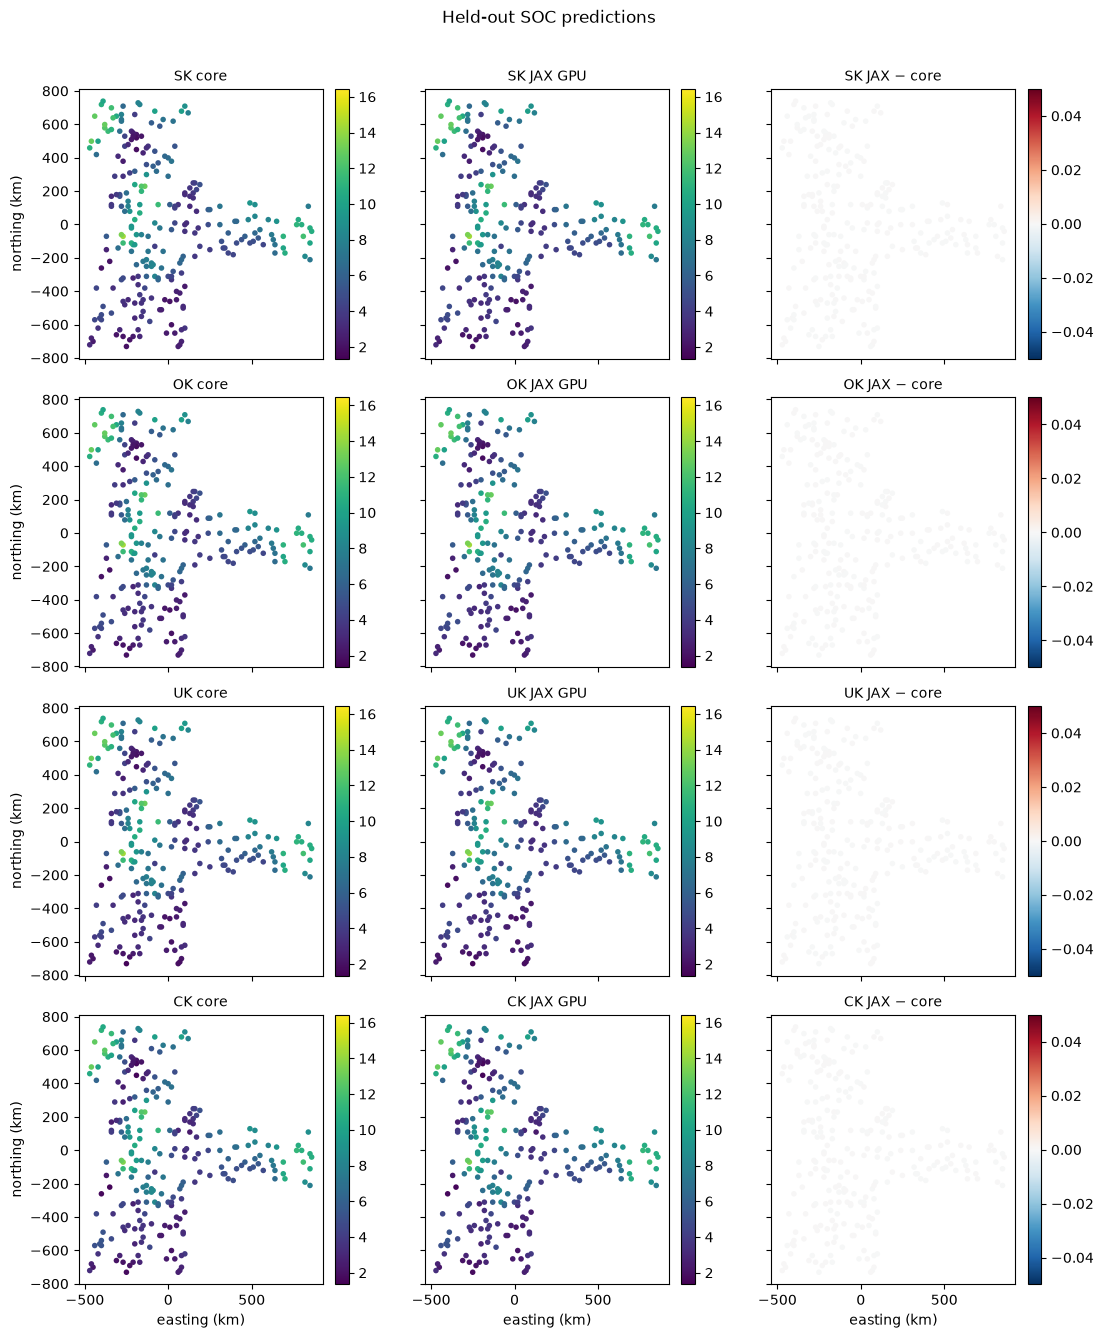

In [5]:
vmin, vmax = np.quantile(test_z, [0.02, 0.98])
gap_lim = max(
    0.05,
    np.nanmax([np.max(np.abs(predictions[(m, JAX_MAP)] - predictions[(m, "core CPU")])) for m in methods]),
)

fig, axes = plt.subplots(4, 3, figsize=(11.2, 13.2), sharex=True, sharey=True)
for row, method in enumerate(methods):
    core_pred = predictions[(method, "core CPU")]
    jax_pred = predictions[(method, JAX_MAP)]
    panels = [
        (core_pred, "viridis", vmin, vmax, f"{method} core"),
        (jax_pred, "viridis", vmin, vmax, f"{method} {JAX_MAP}"),
        (jax_pred - core_pred, "RdBu_r", -gap_lim, gap_lim, f"{method} JAX − core"),
    ]
    for col, (values, cmap, lo, hi, title) in enumerate(panels):
        ax = axes[row, col]
        sc = ax.scatter(test_xy[:, 0], test_xy[:, 1], c=values, s=16, cmap=cmap, vmin=lo, vmax=hi, linewidths=0)
        ax.set_aspect("equal")
        ax.set_title(title, fontsize=10)
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        if row == 3:
            ax.set_xlabel("easting (km)")
        if col == 0:
            ax.set_ylabel("northing (km)")
fig.suptitle("Held-out SOC predictions", y=1.01)
fig.tight_layout()
plt.show()


## Comparison

The scatter plots put the core prediction on the x-axis and the JAX prediction on the y-axis. A point on the diagonal is the same number from both solvers. RMSE in the table above is against the observed SOC at those sites.


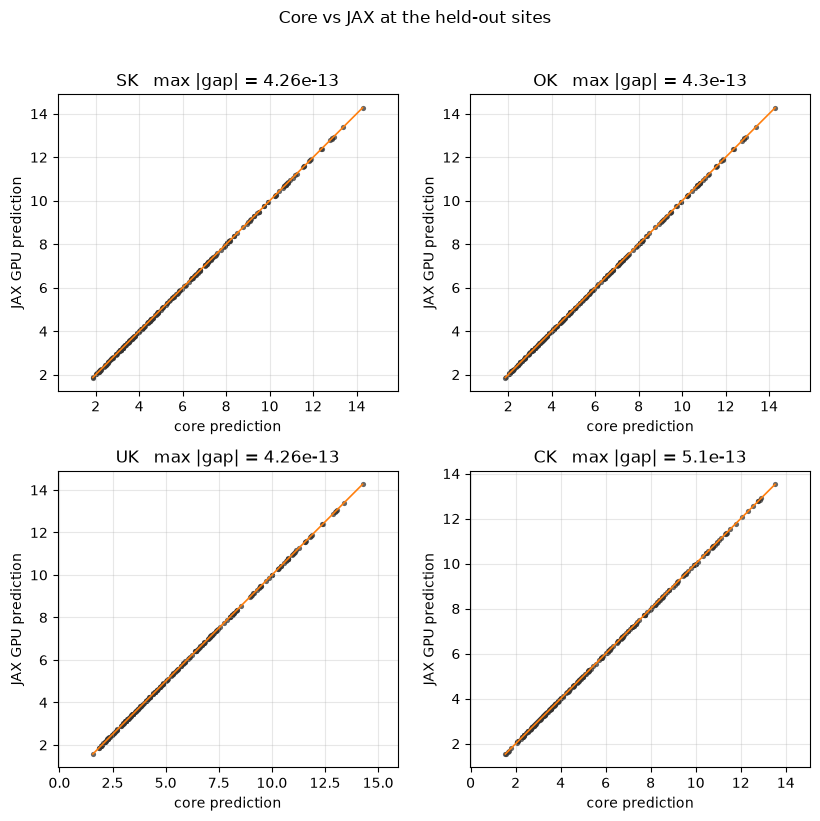

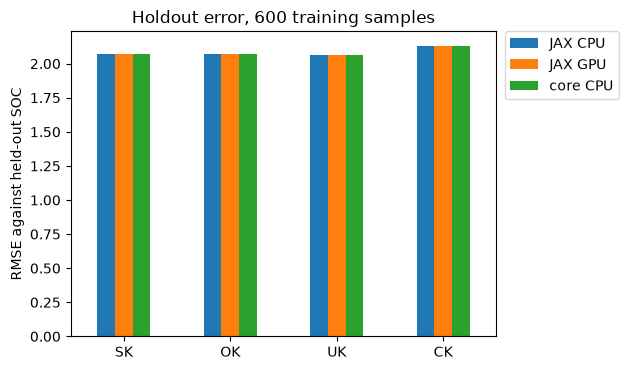

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(8.4, 8.0))
for ax, method in zip(axes.ravel(), methods):
    core_pred = predictions[(method, "core CPU")]
    jax_pred = predictions[(method, JAX_MAP)]
    ax.scatter(core_pred, jax_pred, s=14, c="0.2", alpha=0.75, linewidths=0)
    lo = min(core_pred.min(), jax_pred.min())
    hi = max(core_pred.max(), jax_pred.max())
    ax.plot([lo, hi], [lo, hi], color="C1", lw=1.2)
    gap = np.max(np.abs(jax_pred - core_pred))
    ax.set_title(f"{method}   max |gap| = {gap:.3g}")
    ax.set_xlabel("core prediction")
    ax.set_ylabel(f"{JAX_MAP} prediction")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True, alpha=0.3)
fig.suptitle("Core vs JAX at the held-out sites", y=1.02)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.4, 3.8))
wide = scores.pivot(index="method", columns="backend", values="RMSE").loc[methods]
wide.plot(kind="bar", ax=ax, rot=0)
ax.set_ylabel("RMSE against held-out SOC")
ax.set_xlabel("")
ax.set_title(f"Holdout error, {N_TRAIN} training samples")
ax.legend(title="", loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0)
fig.tight_layout()
plt.show()


## Timing

Kriging cost grows with the number of training points `n` (the covariance matrix is n by n) and the number of prediction points `m` (one cross-covariance row per point). The JAX classes split the work the same way: `fit` builds the covariance matrix and factors it once (a Cholesky factorization kept on the device), and `predict` runs compiled kernels that only need the cross-covariances. So the timing below predicts on a 200 by 200 grid (40,000 cells) over the study area, with ordinary kriging at four training sizes and the other estimators at 2,000 training points.

Each row reports `fit + first predict (s)`, which includes the JAX compilation on the first call, and `predict (s)`, the median of two later `predict` calls on the same model, which is what a user pays for every further map. Four backends are compared: the NumPy core on the CPU, JAX on the CPU, JAX on the GPU in float64 and JAX on the GPU in float32 (`dtype="float32"`). The last column is the largest difference from the core prediction on the grid.

OK  n=500   core CPU         first   0.694s  predict   0.866s  max|diff| 0.0e+00


OK  n=500   JAX CPU          first   0.546s  predict   0.050s  max|diff| 1.0e-12


OK  n=500   JAX GPU          first   2.275s  predict   0.013s  max|diff| 1.0e-12


OK  n=500   JAX GPU float32  first   1.290s  predict   0.021s  max|diff| 4.4e-03


OK  n=1000  core CPU         first   1.522s  predict   1.532s  max|diff| 0.0e+00


OK  n=1000  JAX CPU          first   0.550s  predict   0.070s  max|diff| 4.7e-12


... (19 outputs left out)

CK  n=2000  JAX CPU          first   1.107s  predict   0.466s  max|diff| 3.9e-12


CK  n=2000  JAX GPU          first   1.561s  predict   0.057s  max|diff| 4.0e-12


CK  n=2000  JAX GPU float32  first   1.187s  predict   0.159s  max|diff| 5.6e-03


,method,n,backend,fit + first predict (s),predict (s),max |diff| vs core,speed-up vs core
0,OK,500,core CPU,0.694,0.866,0.000000e+00,1.0
1,OK,500,JAX CPU,0.546,0.050,1.032063e-12,17.3
2,OK,500,JAX GPU,2.275,0.013,1.035616e-12,65.4
3,OK,500,JAX GPU float32,1.290,0.021,4.367903e-03,41.6
4,OK,1000,core CPU,1.522,1.532,0.000000e+00,1.0
5,OK,1000,JAX CPU,0.550,0.070,4.680700e-12,22.0
6,OK,1000,JAX GPU,1.863,0.020,4.652279e-12,77.9
7,OK,1000,JAX GPU float32,1.193,0.031,3.934315e-03,48.7
8,OK,2000,core CPU,3.623,4.069,0.000000e+00,1.0
9,OK,2000,JAX CPU,0.721,0.162,6.052048e-12,25.2


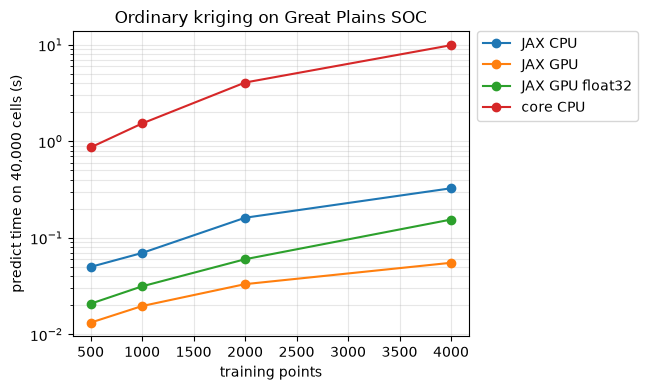

In [7]:
# Timing on a 200 x 200 prediction grid over the sample extent.
GRID_N = 200  # grid cells per side, 40,000 prediction points in total
gx = np.linspace(xy[:, 0].min(), xy[:, 0].max(), GRID_N)  # grid easting (km)
gy = np.linspace(xy[:, 1].min(), xy[:, 1].max(), GRID_N)  # grid northing (km)
grid_xy = np.stack(np.meshgrid(gx, gy), axis=-1).reshape(-1, 2)  # prediction points


def build_model(method, n_train, use_gpu, jax_backend, dtype=None):
    """A fitted kriging model on the first n_train samples (core or JAX)."""
    xy_n, z_n, s_n = xy[:n_train], soc[:n_train], ndvi[:n_train]  # training subset
    if jax_backend:
        kw = {} if dtype is None else {"dtype": dtype}  # float32 only when asked
        primary = with_core_params(jx.Variogram, xy_n, z_n, core_soc, use_gpu)  # SOC variogram
        if method == "SK":
            return jx.SimpleKriging(primary, mean=float(z_n.mean()), use_gpu=use_gpu, **kw).fit(xy_n, z_n)
        if method == "OK":
            return jx.OrdinaryKriging(primary, use_gpu=use_gpu, **kw).fit(xy_n, z_n)
        if method == "UK":
            return jx.UniversalKriging(primary, degree=1, use_gpu=use_gpu, **kw).fit(xy_n, z_n)
        secondary = with_core_params(jx.Variogram, xy_n, s_n, core_ndvi, use_gpu)  # NDVI variogram
        cross = jx.CrossVariogram(xy_n, z_n, s_n, model=MODEL, maxlag=MAXLAG, n_lags=N_LAGS, use_gpu=use_gpu)
        cross.set_params(*[float(v) for v in core_cross.fitted_params])  # core cross-variogram parameters
        return jx.Cokriging(primary, secondary, cross, use_gpu=use_gpu, **kw).fit(xy_n, z_n, xy_n, s_n)
    if method == "SK":
        return CoreSK(core_soc, mean=float(z_n.mean()), use_gpu=False).fit(xy_n, z_n)
    if method == "OK":
        return CoreOK(core_soc, use_gpu=False).fit(xy_n, z_n)
    if method == "UK":
        return CoreUK(core_soc, degree=1, use_gpu=False).fit(xy_n, z_n)
    return CoreCK(core_soc, core_ndvi, core_cross, use_gpu=False).fit(xy_n, z_n, xy_n, s_n)


def time_backend(method, n_train, use_gpu, jax_backend, dtype=None, repeats=2):
    """(fit + first predict, steady predict, predictions) for one backend."""
    t0 = time.perf_counter()  # start of fit + first predict
    model = build_model(method, n_train, use_gpu, jax_backend, dtype)  # factor once
    pred = model.predict(grid_xy)  # first call compiles the JAX kernels
    first = time.perf_counter() - t0  # seconds for fit + first predict
    steady = []  # later calls reuse the factor and the compiled kernels
    for _ in range(repeats):
        t0 = time.perf_counter()
        model.predict(grid_xy)
        steady.append(time.perf_counter() - t0)
    return first, float(np.median(steady)), np.asarray(pred, dtype=float)


jobs = [("core CPU", False, False, None), ("JAX CPU", False, True, None)]  # (label, use_gpu, jax, dtype)
if gpu_devices:
    jobs += [("JAX GPU", True, True, None), ("JAX GPU float32", True, True, "float32")]

plan = [("OK", n) for n in (500, 1000, 2000, 4000)] + [("SK", 2000), ("UK", 2000), ("CK", 2000)]
timing_rows = []
for method, n in plan:
    core_pred = None
    for label, use_gpu, jax_backend, dtype in jobs:
        first, steady, pred = time_backend(method, n, use_gpu, jax_backend, dtype)
        if core_pred is None:
            core_pred = pred  # the core CPU run comes first and is the reference
        gap = float(np.max(np.abs(pred - core_pred)))  # largest difference from the core map
        timing_rows.append({"method": method, "n": n, "backend": label, "fit + first predict (s)": first,
                            "predict (s)": steady, "max |diff| vs core": gap})
        print(f"{method:3s} n={n:<5d} {label:16s} first {first:7.3f}s  predict {steady:7.3f}s  max|diff| {gap:.1e}")

timing = pd.DataFrame(timing_rows)  # one row per method, size and backend
core_time = timing[timing["backend"] == "core CPU"].set_index(["method", "n"])["predict (s)"]
timing["speed-up vs core"] = [core_time[(m, n)] / t for m, n, t in zip(timing["method"], timing["n"], timing["predict (s)"])]
display(timing.round({"fit + first predict (s)": 3, "predict (s)": 3, "speed-up vs core": 1}))

fig, ax = plt.subplots(figsize=(6.6, 4.0))
part = timing[timing["method"] == "OK"].pivot(index="n", columns="backend", values="predict (s)")
part.plot(marker="o", ax=ax, logy=True)  # log scale: the backends differ by orders of magnitude
ax.set_xlabel("training points")
ax.set_ylabel("predict time on 40,000 cells (s)")
ax.set_title("Ordinary kriging on Great Plains SOC")
ax.grid(True, which="both", alpha=0.3)
ax.legend(title="", loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0)
fig.tight_layout()
plt.show()

## Getting good performance from JAX kriging

The timing table shows when the JAX classes pay off and when the NumPy core is enough.

- Fit once and predict many times. `fit` factors the covariance matrix; every later `predict` reuses the factor and the compiled kernels, so a second map, a finer grid or a set of validation points costs only the cross-covariances.
- Expect a one-time cost on the first call. JAX compiles each kernel the first time it sees a model and a batch size, which takes about a second. Variogram parameters are passed to the kernels as data, and prediction points are padded to one of a few batch sizes (powers of two), so new parameters or a similar number of points reuse the compiled kernels. Setting `jax.config.update("jax_compilation_cache_dir", "~/.cache/jax")` keeps the compiled kernels on disk between sessions.
- Use the GPU for large problems. With a few hundred training points and a few hundred prediction points the arithmetic is too small to keep a GPU busy, and the core or JAX on the CPU is just as fast.
- Use `dtype="float32"` when you need kriging variances on a consumer or laptop GPU. These GPUs run float64 at a small fraction of their float32 speed, and with `return_variance=True` the float32 solve was 10 to 15 times faster than float64 on 2,000 to 5,000 training points. For predictions alone, as in the table, float64 is already one matrix-vector product per batch and float32 is no faster. Float32 predictions differ from float64 by a few thousandths of a SOC unit (the last column); check that difference on your own data before using float32 for a final map.
- Ask for variances only when you need them. `predict(..., return_variance=True)` adds a triangular solve with the factor for every prediction point, which on the GPU made ordinary kriging with 2,000 training points about 20 times slower (0.67 s instead of 0.033 s for 40,000 cells).

## Reading the figures

The variogram panel is the spatial structure used by every solver: SOC and NDVI rise toward a sill inside the 800 km window, and the cross-variogram is positive, which is why NDVI is a usable secondary. The prediction maps are the held-out sites, not a filled raster, because the 5,000 samples do not sit on a regular grid. Where the JAX minus core map is pale, the two solvers returned the same SOC. The scatter plots make the same check one point at a time. RMSE is the error against the laboratory SOC, so it can be large even when the two solvers agree. In the timing table, the first column includes the factorization and the JAX compilation, and the predict column is the cost of every later map from the same fitted model.
